# Métriques d'évaluation en NLP : démonstration

Ce notebook évalue **trois vrais systèmes** sur **trois tâches** de traitement du langage naturel :

| Tâche | Système | Données | Métriques |
|---|---|---|---|
| 1. Classification (détection de spam) | TF-IDF + Régression logistique, entraînée ici | SMS Spam Collection (UCI) | Accuracy, Précision, Rappel, F1 |
| 2. Traduction automatique (anglais → français) | MarianMT `opus-mt-en-fr` (réseau de neurones Transformer, version compressée ONNX) | WMT14 newstest2014 | BLEU |
| 3. Résumé automatique | TextRank (algorithme extractif) comparé à deux baselines | CNN/DailyMail | ROUGE-1, ROUGE-2, ROUGE-L |

Principe commun : on compare **ce que le système produit** avec **ce qui était attendu** (la référence humaine).

In [1]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.donnees import charger_sms_spam, charger_wmt14, charger_cnn_dailymail

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
BLEU_C, VERT, ROUGE_C, GRIS = "#2B6CB0", "#2F855A", "#C53030", "#94A3B8"
Path("figures").mkdir(exist_ok=True); Path("results").mkdir(exist_ok=True)
resultats = {}

---
## 1. Classification : détection de spam

**Définition.** Classer un texte dans une catégorie parmi une liste fixe.
Ici : un SMS est-il un **spam** ou un message **normal** (*ham*) ?

### 1.1 Les données

In [2]:
df = charger_sms_spam()
print(f"{len(df)} SMS")
print(df["label"].value_counts(normalize=True).round(3))
df.sample(5, random_state=1)

5574 SMS
label
ham     0.866
spam    0.134
Name: proportion, dtype: float64


,label,texte
1447,ham,Looks like u wil b getting a headstart im leaving here bout 2.30ish but if u r desperate for my company I could head...
2032,ham,"I noe la... U wana pei bf oso rite... K lor, other days den..."
4432,ham,2mro i am not coming to gym machan. Goodnight.
4888,spam,Todays Vodafone numbers ending with 4882 are selected to a receive a £350 award. If your number matches call 0906401...
5276,ham,"Hi. Hope ur day * good! Back from walk, table booked for half eight. Let me know when ur coming over."


### 1.2 Entraîner un vrai classifieur

- **TF-IDF** : transforme chaque SMS en vecteur de nombres (poids de chaque mot).
- **Régression logistique** : apprend à séparer spam et normal à partir de ces vecteurs.
- On garde 20 % des SMS de côté (**jeu de test**) : le modèle ne les voit jamais pendant l'entraînement.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

X_train, X_test, y_train, y_test = train_test_split(
    df["texte"], (df["label"] == "spam").astype(int),
    test_size=0.2, stratify=df["label"], random_state=42)

modele = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))
t0 = time.time()
modele.fit(X_train, y_train)
print(f"Entraînement : {len(X_train)} SMS en {time.time() - t0:.1f} s")
print(f"Test : {len(X_test)} SMS, dont {y_test.sum()} spams")

y_pred = modele.predict(X_test)

Entraînement : 4459 SMS en 0.1 s
Test : 1115 SMS, dont 149 spams


### 1.3 La matrice de confusion, calculée à la main

On compte les 4 cas possibles (classe positive = **spam**) :

| | Prédit spam | Prédit normal |
|---|---|---|
| **Vrai spam** | VP (vrai positif) | FN (faux négatif : spam raté) |
| **Vrai normal** | FP (faux positif : fausse alerte) | VN (vrai négatif) |

Puis :
- **Accuracy** = (VP + VN) / total : la part de bonnes réponses
- **Précision** = VP / (VP + FP) : quand le modèle dit « spam », a-t-il raison ?
- **Rappel** = VP / (VP + FN) : parmi les vrais spams, combien sont détectés ?
- **F1** = 2 × Précision × Rappel / (Précision + Rappel) : la moyenne harmonique des deux

In [4]:
y_true = y_test.to_numpy()
VP = int(((y_pred == 1) & (y_true == 1)).sum())
FP = int(((y_pred == 1) & (y_true == 0)).sum())
FN = int(((y_pred == 0) & (y_true == 1)).sum())
VN = int(((y_pred == 0) & (y_true == 0)).sum())
print(f"VP={VP}  FP={FP}  FN={FN}  VN={VN}")

accuracy  = (VP + VN) / (VP + VN + FP + FN)
precision = VP / (VP + FP)
rappel    = VP / (VP + FN)
f1        = 2 * precision * rappel / (precision + rappel)
print(f"Accuracy  = {accuracy:.3f}")
print(f"Précision = {precision:.3f}")
print(f"Rappel    = {rappel:.3f}")
print(f"F1        = {f1:.3f}")

VP=121  FP=0  FN=28  VN=966
Accuracy  = 0.975
Précision = 1.000
Rappel    = 0.812
F1        = 0.896


On vérifie avec scikit-learn : on doit trouver exactement les mêmes chiffres.

accuracy=0.975  precision=1.000  recall=0.812  f1=0.896


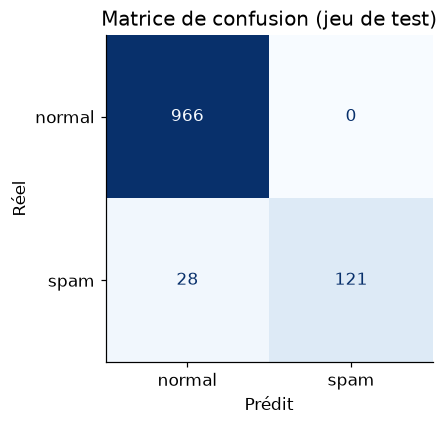

In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
print(f"accuracy={accuracy_score(y_true, y_pred):.3f}  precision={precision_score(y_true, y_pred):.3f}  "
      f"recall={recall_score(y_true, y_pred):.3f}  f1={f1_score(y_true, y_pred):.3f}")

fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=["normal", "spam"], cmap="Blues", colorbar=False, ax=ax)
ax.set_xlabel("Prédit"); ax.set_ylabel("Réel"); ax.set_title("Matrice de confusion (jeu de test)")
plt.tight_layout(); plt.savefig("figures/matrice_confusion.png", dpi=200); plt.show()

### 1.4 Le piège de l'accuracy

Un « modèle » qui répond **toujours « normal »** ne détecte aucun spam.
Pourtant son accuracy est très élevée, car 87 % des SMS sont normaux.

In [6]:
from sklearn.dummy import DummyClassifier
naif = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
y_naif = naif.predict(X_test)

def scores(y, p):
    return {"Accuracy": accuracy_score(y, p), "Précision": precision_score(y, p, zero_division=0),
            "Rappel": recall_score(y, p), "F1": f1_score(y, p)}

comparaison = pd.DataFrame({"Toujours « normal »": scores(y_true, y_naif),
                            "TF-IDF + Régression logistique": scores(y_true, y_pred)}).T.round(3)
comparaison

,Accuracy,Précision,Rappel,F1
Toujours « normal »,0.866,0.0,0.000,0.000
TF-IDF + Régression logistique,0.975,1.0,0.812,0.896


### 1.5 Le seuil de décision : précision ou rappel ?

Le modèle donne une **probabilité** de spam. Par défaut, on dit « spam » au-dessus de 0,5.
Baisser le seuil attrape plus de spams (rappel ↑) mais crée plus de fausses alertes (précision ↓).

In [7]:
proba = modele.predict_proba(X_test)[:, 1]
seuils = pd.DataFrame([{"Seuil": s, **scores(y_true, (proba >= s).astype(int))} for s in [0.2, 0.3, 0.5, 0.7]]).round(3)
seuils

,Seuil,Accuracy,Précision,Rappel,F1
0,0.2,0.978,0.903,0.940,0.921
1,0.3,0.985,0.971,0.913,0.941
2,0.5,0.975,1.000,0.812,0.896
3,0.7,0.943,1.000,0.577,0.732


In [8]:
erreurs = pd.DataFrame({"texte": X_test, "vrai": y_true, "predit": y_pred})
print("Spams ratés (faux négatifs) :")
for t in erreurs.query("vrai == 1 and predit == 0")["texte"].head(3): print("  -", t[:110])
fp = erreurs.query("vrai == 0 and predit == 1")["texte"]
print(f"Fausses alertes (faux positifs) : {len(fp)}")
for t in fp.head(3): print("  -", t[:110])

resultats["classification"] = {
    "n_sms": len(df), "part_spam": round(float(df["label"].eq("spam").mean()), 4),
    "n_train": len(X_train), "n_test": len(X_test), "spams_test": int(y_test.sum()),
    "confusion": {"VP": VP, "FP": FP, "FN": FN, "VN": VN},
    "modele": comparaison.iloc[1].to_dict(), "naif": comparaison.iloc[0].to_dict(),
    "seuils": seuils.to_dict(orient="records"),
}

Spams ratés (faux négatifs) :
  - Ever thought about living a good life with a perfect partner? Just txt back NAME and AGE to join the mobile co
  - Your weekly Cool-Mob tones are ready to download !This weeks new Tones include: 1) Crazy Frog-AXEL F>>> 2) Ako
  - Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond y
Fausses alertes (faux positifs) : 0


---
## 2. Traduction automatique : BLEU

**Définition.** Transformer un texte d'une langue source (anglais) vers une langue cible (français), en gardant le sens.

**BLEU** (*Bilingual Evaluation Understudy*, 2002) compare la traduction de la machine à une traduction humaine :
1. On compte les **n-grammes** communs (suites de 1, 2, 3 et 4 mots) : c'est une **précision**.
2. On fait la moyenne géométrique des 4 précisions.
3. On multiplie par une **pénalité de brièveté** : sinon, une traduction très courte tricherait.

Score entre 0 et 100. Plus c'est haut, plus la traduction ressemble à la référence.

### 2.1 Exemple simple

In [9]:
import sacrebleu
reference = "Le chat dort sur le canapé ."
candidats = {
    "identique": "Le chat dort sur le canapé .",
    "un mot change": "Le chat dort sur le sofa .",
    "même sens, autres mots": "Le matou fait la sieste sur le divan .",
    "hors sujet": "Un chien mange dans la cuisine .",
}
for nom, c in candidats.items():
    b = sacrebleu.sentence_bleu(c, [reference])
    print(f"{nom:24s} BLEU = {b.score:5.1f}   {c}")

identique                BLEU = 100.0   Le chat dort sur le canapé .
un mot change            BLEU =  64.3   Le chat dort sur le sofa .
même sens, autres mots   BLEU =  11.3   Le matou fait la sieste sur le divan .
hors sujet               BLEU =   6.6   Un chien mange dans la cuisine .


Limite visible : « Le matou fait la sieste sur le divan » a **le même sens** mais un BLEU bas.
BLEU mesure les **mots en commun**, pas le sens.

### 2.2 Évaluation d'un vrai modèle : MarianMT

- Modèle : `Helsinki-NLP/opus-mt-en-fr`, un **Transformer** entraîné sur des millions de phrases (corpus OPUS).
- Version compressée (ONNX, int8) : environ 110 Mo, tourne sur CPU.
- Données : 100 phrases du jeu de test **WMT14** (articles de presse), avec leur traduction humaine.

In [10]:
wmt = charger_wmt14(100)
wmt.head(3)

,en,fr
0,Spectacular Wingsuit Jump Over Bogota,"Spectaculaire saut en ""wingsuit"" au-dessus de Bogota"
1,"Sportsman Jhonathan Florez jumped from a helicopter above Bogota, the capital of Colombia, on Thursday.","Le sportif Jhonathan Florez a sauté jeudi d'un hélicoptère au-dessus de Bogota, la capitale colombienne."
2,"Wearing a wingsuit, he flew past over the famous Monserrate Sanctuary at 160km/h. The sanctuary is located at an alt...","Equipé d'un wingsuit (une combinaison munie d'ailes), il est passé à 160 km/h au-dessus du célèbre sanctuaire Monser..."


In [11]:
from src.traduction import TraducteurMarian

cache = Path("data/traductions_marian_100.json")
if cache.exists():
    hypotheses = json.loads(cache.read_text(encoding="utf-8"))
else:
    traducteur = TraducteurMarian()
    t0, hypotheses = time.time(), []
    for i, phrase in enumerate(wmt["en"]):
        hypotheses.append(traducteur.traduire(phrase))
        if (i + 1) % 25 == 0: print(f"{i + 1}/100 phrases traduites ({time.time() - t0:.0f} s)")
    cache.write_text(json.dumps(hypotheses, ensure_ascii=False, indent=1), encoding="utf-8")

wmt["marian"] = hypotheses
wmt[["en", "marian", "fr"]].head(3).rename(columns={"en": "anglais", "marian": "MarianMT", "fr": "référence humaine"})

,anglais,MarianMT,référence humaine
0,Spectacular Wingsuit Jump Over Bogota,Spectaculaire Wingsuit Jump sur Bogota,"Spectaculaire saut en ""wingsuit"" au-dessus de Bogota"
1,"Sportsman Jhonathan Florez jumped from a helicopter above Bogota, the capital of Colombia, on Thursday.","Le sportif Jhonathan Florez a sauté d'un hélicoptère au-dessus de Bogota, la capitale de la Colombie, jeudi.","Le sportif Jhonathan Florez a sauté jeudi d'un hélicoptère au-dessus de Bogota, la capitale colombienne."
2,"Wearing a wingsuit, he flew past over the famous Monserrate Sanctuary at 160km/h. The sanctuary is located at an alt...","Portant un wingsuit, il a survolé le célèbre sanctuaire Monserrate à 160km/h. Le sanctuaire est situé à une altitude...","Equipé d'un wingsuit (une combinaison munie d'ailes), il est passé à 160 km/h au-dessus du célèbre sanctuaire Monser..."


In [12]:
bleu = sacrebleu.corpus_bleu(wmt["marian"].tolist(), [wmt["fr"].tolist()])
print(bleu)
print()
print("Précisions n-grammes :", [round(p, 1) for p in bleu.precisions], "(1, 2, 3, 4 mots)")
print(f"Pénalité de brièveté : {bleu.bp:.3f}   (longueur machine {bleu.sys_len} / référence {bleu.ref_len})")

BLEU = 38.60 66.5/45.0/33.3/25.1 (BP = 0.971 ratio = 0.971 hyp_len = 2341 ref_len = 2410)

Précisions n-grammes : [66.5, 45.0, 33.3, 25.1] (1, 2, 3, 4 mots)
Pénalité de brièveté : 0.971   (longueur machine 2341 / référence 2410)


### 2.3 BLEU phrase par phrase

Le score global cache de grosses différences entre les phrases.

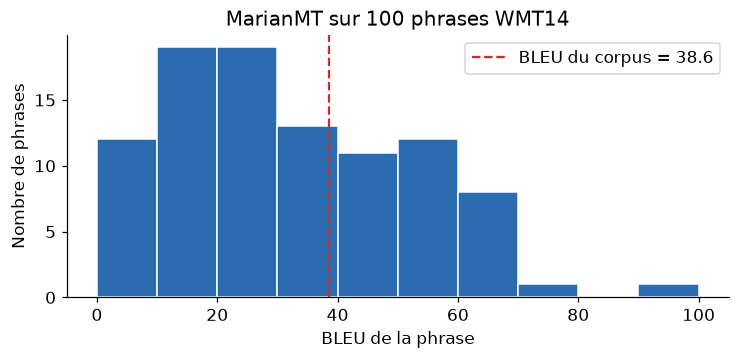

Meilleures phrases :


,anglais,MarianMT,référence,BLEU
3,A black box in your car?,Une boîte noire dans votre voiture ?,Une boîte noire dans votre voiture ?,100.0
16,The technology is there to do it.,La technologie est là pour le faire.,La technologie est là pour le faire.,100.0


Moins bonnes phrases :


,anglais,MarianMT,référence,BLEU
84,Previously Unpublished Tracks Released,Les pistes inédites publiées antérieurement,Des inédits déjà en écoute,0.0
29,The free marketeers at the Reason Foundation are also fond of having drivers pay per mile.,Les marketeurs libres de la Fondation Raison aiment aussi avoir des chauffeurs à payer par mille.,Les partisans du marché libre de la fondation Reason apprécient également l'idée de faire payer les conducteurs au mile.,4.8


In [13]:
wmt["bleu"] = [sacrebleu.sentence_bleu(h, [r]).score for h, r in zip(wmt["marian"], wmt["fr"])]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(wmt["bleu"], bins=10, range=(0, 100), color=BLEU_C, edgecolor="white")
ax.axvline(bleu.score, color=ROUGE_C, ls="--", label=f"BLEU du corpus = {bleu.score:.1f}")
ax.set_xlabel("BLEU de la phrase"); ax.set_ylabel("Nombre de phrases"); ax.legend()
ax.set_title("MarianMT sur 100 phrases WMT14")
plt.tight_layout(); plt.savefig("figures/bleu_histogramme.png", dpi=200); plt.show()

pd.set_option("display.max_colwidth", 200)
cols = {"en": "anglais", "marian": "MarianMT", "fr": "référence", "bleu": "BLEU"}
print("Meilleures phrases :"); display(wmt.nlargest(2, "bleu")[list(cols)].rename(columns=cols).round(1))
print("Moins bonnes phrases :"); display(wmt.nsmallest(2, "bleu")[list(cols)].rename(columns=cols).round(1))

In [14]:
hist, _ = np.histogram(wmt["bleu"], bins=10, range=(0, 100))
pire = wmt.nsmallest(1, "bleu").iloc[0]
meilleure = wmt.nlargest(1, "bleu").iloc[0]
resultats["traduction"] = {
    "n_phrases": len(wmt), "bleu": round(bleu.score, 1), "precisions": [round(p, 1) for p in bleu.precisions],
    "bp": round(bleu.bp, 3), "sys_len": bleu.sys_len, "ref_len": bleu.ref_len,
    "exemple_jouet": {nom: round(sacrebleu.sentence_bleu(c, [reference]).score, 1) for nom, c in candidats.items()},
    "histogramme": hist.tolist(),
    "meilleure": {k: (round(float(meilleure[k]), 1) if k == "bleu" else meilleure[k]) for k in ["en", "marian", "fr", "bleu"]},
    "pire": {k: (round(float(pire[k]), 1) if k == "bleu" else pire[k]) for k in ["en", "marian", "fr", "bleu"]},
}

---
## 3. Résumé automatique : ROUGE

**Définition.** Produire une version courte d'un texte qui garde l'essentiel.
- **Extractif** : on recopie les phrases les plus importantes du texte.
- **Abstractif** : on réécrit avec ses propres mots.

**ROUGE** (*Recall-Oriented Understudy for Gisting Evaluation*, 2004) compare le résumé de la machine à un résumé humain :
- **ROUGE-1** : mots en commun
- **ROUGE-2** : paires de mots consécutifs (bigrammes) en commun
- **ROUGE-L** : plus longue sous-séquence commune (respecte l'ordre des mots)

Pour chacun : rappel (la part de la référence retrouvée), précision, et F1. On rapporte le **F1**.

### 3.1 Exemple simple

In [15]:
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

ref = "Police arrested two men after the bank robbery in Paris."
for cand in ["Two men were arrested by police after the Paris bank robbery.",
             "The weather in Paris was sunny on Monday."]:
    s = scorer.score(ref, cand)
    print(cand)
    for k, v in s.items():
        print(f"   {k:7s} précision={v.precision:.2f}  rappel={v.recall:.2f}  F1={v.fmeasure:.2f}")

Two men were arrested by police after the Paris bank robbery.
   rouge1  précision=0.82  rappel=0.90  F1=0.86
   rouge2  précision=0.30  rappel=0.33  F1=0.32
   rougeL  précision=0.55  rappel=0.60  F1=0.57
The weather in Paris was sunny on Monday.
   rouge1  précision=0.38  rappel=0.30  F1=0.33
   rouge2  précision=0.14  rappel=0.11  F1=0.12
   rougeL  précision=0.38  rappel=0.30  F1=0.33


### 3.2 Évaluation sur de vrais articles

- Données : 30 articles du jeu de test **CNN/DailyMail**, chacun avec un résumé écrit par un journaliste.
- On compare trois systèmes extractifs, qui choisissent chacun **3 phrases** :
  - **Aléatoire** : 3 phrases au hasard (borne basse)
  - **Lead-3** : les 3 premières phrases (baseline classique : les journalistes écrivent l'essentiel au début)
  - **TextRank** : algorithme de graphe (inspiré de PageRank de Google) qui garde les phrases les plus « centrales »

In [16]:
import nltk
for pkg in ["punkt", "punkt_tab"]: nltk.download(pkg, quiet=True)
from nltk.tokenize import sent_tokenize
from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer
from sumy.summarizers.text_rank import TextRankSummarizer

cnn = charger_cnn_dailymail(30)
textrank = TextRankSummarizer()
rng = np.random.default_rng(0)

def resume_lead3(article):
    return " ".join(sent_tokenize(article)[:3])

def resume_textrank(article):
    doc = PlaintextParser.from_string(article, Tokenizer("english")).document
    return " ".join(str(s) for s in textrank(doc, 3))

def resume_aleatoire(article):
    phrases = sent_tokenize(article)
    idx = sorted(rng.choice(len(phrases), size=min(3, len(phrases)), replace=False))
    return " ".join(phrases[i] for i in idx)

systemes = {"Aléatoire": resume_aleatoire, "Lead-3": resume_lead3, "TextRank": resume_textrank}
for nom, f in systemes.items():
    cnn[nom] = [f(a) for a in cnn["article"]]
print(f"{len(cnn)} articles, {cnn['article'].str.split().str.len().mean():.0f} mots en moyenne ; "
      f"résumé de référence : {cnn['reference'].str.split().str.len().mean():.0f} mots")
mots_resumes = {nom: round(float(cnn[nom].str.split().str.len().mean())) for nom in systemes}
print("Longueur moyenne des résumés produits (mots) :", mots_resumes)

30 articles, 563 mots en moyenne ; résumé de référence : 36 mots
Longueur moyenne des résumés produits (mots) : {'Aléatoire': 59, 'Lead-3': 61, 'TextRank': 96}


In [17]:
lignes = []
for nom in systemes:
    s = [scorer.score(r, h) for r, h in zip(cnn["reference"], cnn[nom])]
    lignes.append({"Système": nom, **{m.upper().replace("ROUGE", "ROUGE-"): 100 * np.mean([x[m].fmeasure for x in s]) for m in ["rouge1", "rouge2", "rougeL"]}})
rouge_tab = pd.DataFrame(lignes).set_index("Système").round(1)
rouge_tab

,ROUGE-1,ROUGE-2,ROUGE-L
Système,,,
Aléatoire,24.2,6.4,15.0
Lead-3,29.3,10.8,20.2
TextRank,22.4,5.9,15.3


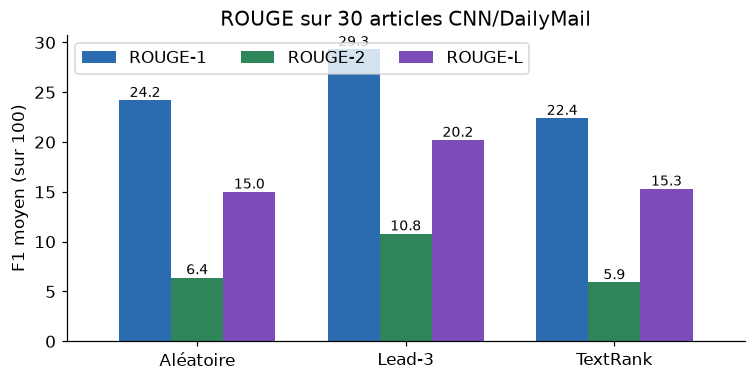

In [18]:
ax = rouge_tab.plot.bar(figsize=(7, 3.6), color=[BLEU_C, VERT, "#7C4DBA"], rot=0, width=0.75)
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=9)
ax.set_ylabel("F1 moyen (sur 100)"); ax.set_xlabel(""); ax.set_title("ROUGE sur 30 articles CNN/DailyMail")
ax.legend(ncol=3, loc="upper left")
plt.tight_layout(); plt.savefig("figures/rouge_comparaison.png", dpi=200); plt.show()

### 3.3 Un exemple concret

In [19]:
i = 0
print("RÉFÉRENCE (journaliste) :\n", cnn.loc[i, "reference"], "\n")
for nom in ["Lead-3", "TextRank"]:
    s = scorer.score(cnn.loc[i, "reference"], cnn.loc[i, nom])
    print(f"{nom}  (ROUGE-1 = {100 * s['rouge1'].fmeasure:.1f}, ROUGE-2 = {100 * s['rouge2'].fmeasure:.1f}) :\n", cnn.loc[i, nom][:500], "\n")

resultats["resume"] = {
    "n_articles": len(cnn), "mots_article": round(float(cnn["article"].str.split().str.len().mean())),
    "mots_reference": round(float(cnn["reference"].str.split().str.len().mean())),
    "scores": rouge_tab.to_dict(orient="index"), "mots_resumes": mots_resumes,
    "rappel_precision_r1": {nom: {"rappel": round(100 * np.mean([scorer.score(r, h)["rouge1"].recall for r, h in zip(cnn["reference"], cnn[nom])]), 1),
                                  "precision": round(100 * np.mean([scorer.score(r, h)["rouge1"].precision for r, h in zip(cnn["reference"], cnn[nom])]), 1)}
                            for nom in systemes},
    "exemple_jouet": {c: {k: round(v.fmeasure, 2) for k, v in scorer.score(ref, c).items()}
                      for c in ["Two men were arrested by police after the Paris bank robbery.", "The weather in Paris was sunny on Monday."]},
}

RÉFÉRENCE (journaliste) :
 Membership gives the ICC jurisdiction over alleged crimes committed in Palestinian territories since last June .
Israel and the United States opposed the move, which could open the door to war crimes investigations against Israelis . 

Lead-3  (ROUGE-1 = 29.6, ROUGE-2 = 15.9) :
 (CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, includin 

TextRank  (ROUGE-1 = 14.5, ROUGE-2 = 1.6) :
 "As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to ending a long era of impunity and inju

---
## 4. Bilan

In [20]:
Path("results/metriques.json").write_text(json.dumps(resultats, ensure_ascii=False, indent=1), encoding="utf-8")
pd.DataFrame([
    {"Tâche": "Classification (spam)", "Système": "TF-IDF + Régression logistique", "Métrique principale": "F1",
     "Score": round(100 * resultats["classification"]["modele"]["F1"], 1)},
    {"Tâche": "Traduction EN→FR", "Système": "MarianMT (ONNX)", "Métrique principale": "BLEU",
     "Score": resultats["traduction"]["bleu"]},
    {"Tâche": "Résumé", "Système": "TextRank", "Métrique principale": "ROUGE-1 (F1)",
     "Score": resultats["resume"]["scores"]["TextRank"]["ROUGE-1"]},
])

,Tâche,Système,Métrique principale,Score
0,Classification (spam),TF-IDF + Régression logistique,F1,89.6
1,Traduction EN→FR,MarianMT (ONNX),BLEU,38.6
2,Résumé,TextRank,ROUGE-1 (F1),22.4


**À retenir**

| Tâche | Une seule bonne réponse ? | Métriques | Limite principale |
|---|---|---|---|
| Classification | Oui (une étiquette) | Accuracy, Précision, Rappel, F1 | L'accuracy trompe quand les classes sont déséquilibrées |
| Traduction | Non (plusieurs traductions correctes) | BLEU (précision des n-grammes) | Ne voit pas les synonymes ni le sens |
| Résumé | Non (plusieurs résumés corrects) | ROUGE (rappel des n-grammes) | Récompense le recopiage de mots, pas la qualité de l'écriture |